# SpaceX Falcon 9 Capstone
Executed analysis and original code. See README for scope, disclosure and source limitations.

The IBM datasets differ in population. Results are kept separate. GitHub publication is pending.

## 1. Data collection and API limitation
The live API returned HTTP 522. Analysis uses the preserved IBM API-derived snapshots. The complete live collection implementation is in api_collection.py.

In [1]:
from pathlib import Path
import pandas as pd
raw=pd.read_csv('data/dataset_part_1.csv')
print(raw.shape)
print(raw.head().to_string(index=False))

(90, 17)
 FlightNumber       Date BoosterVersion  PayloadMass Orbit   LaunchSite     Outcome  Flights  GridFins  Reused  Legs LandingPad  Block  ReusedCount Serial   Longitude  Latitude
            1 2010-06-04       Falcon 9  6104.959412   LEO CCAFS SLC 40   None None        1     False   False False        NaN    1.0            0  B0003  -80.577366 28.561857
            2 2012-05-22       Falcon 9   525.000000   LEO CCAFS SLC 40   None None        1     False   False False        NaN    1.0            0  B0005  -80.577366 28.561857
            3 2013-03-01       Falcon 9   677.000000   ISS CCAFS SLC 40   None None        1     False   False False        NaN    1.0            0  B0007  -80.577366 28.561857
            4 2013-09-29       Falcon 9   500.000000    PO  VAFB SLC 4E False Ocean        1     False   False False        NaN    1.0            0  B1003 -120.610829 34.632093
            5 2013-12-03       Falcon 9  3170.000000   GTO CCAFS SLC 40   None None        1     False   F

## 2. Wrangling, exploratory analysis, SQL and predictive modeling
Run the following implementation to reproduce results.json and charts. The output below is from the recorded successful execution. Preprocessing occurs within the CV pipeline.

In [2]:
%run analyze.py

{
  "n": 90,
  "start": "2010-06-04",
  "end": "2020-11-05",
  "positives": 60,
  "site": [
    {
      "LaunchSite": "CCAFS SLC 40",
      "count": 55,
      "sum": 33,
      "mean": 0.6
    },
    {
      "LaunchSite": "KSC LC 39A",
      "count": 22,
      "sum": 17,
      "mean": 0.7727272727272727
    },
    {
      "LaunchSite": "VAFB SLC 4E",
      "count": 13,
      "sum": 10,
      "mean": 0.7692307692307693
    }
  ],
  "orbit": [
    {
      "Orbit": "SO",
      "mean": 0.0,
      "size": 1
    },
    {
      "Orbit": "GTO",
      "mean": 0.5185185185185185,
      "size": 27
    },
    {
      "Orbit": "ISS",
      "mean": 0.6190476190476191,
      "size": 21
    },
    {
      "Orbit": "MEO",
      "mean": 0.6666666666666666,
      "size": 3
    },
    {
      "Orbit": "PO",
      "mean": 0.6666666666666666,
      "size": 9
    },
    {
      "Orbit": "LEO",
      "mean": 0.7142857142857143,
      "size": 7
    },
    {
      "Orbit": "VLEO",
      "mean": 0.857142857142857

### Complete analysis implementation

In [3]:
print(Path('analyze.py').read_text())

from pathlib import Path
import json, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

ROOT=Path(__file__).resolve().parent
DATA=ROOT/'data'; FIG=ROOT/'figures'; FIG.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':12,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':140})
df=pd.read_csv(DATA/'dataset_part_2.csv')
raw=pd.read_c

## 3. Web scraping and interactive visualization
BeautifulSoup parses the saved live Wikipedia HTML. The script creates Folium maps and Plotly chart exports, keeping the 56-row dashboard sample distinct.

In [4]:
%run visuals.py

Wikipedia records: 77
Flight                   UTC       Booster                      Site                                  Payload                                     Mass       Orbit      Customer Mission             Landing
     1     4 June 2010 18:45 F9 v1.0 B0003 Cape Canaveral , SLC ‑ 40     Dragon Spacecraft Qualification Unit                                  Unknown         LEO        SpaceX Success Failure (parachute)
     2 8 December 2010 15:43 F9 v1.0 B0004 Cape Canaveral , SLC ‑ 40  SpaceX COTS Demo Flight 1 (Dragon C101)                                  Unknown         LEO NASA ( COTS ) Success Failure (parachute)
     3     22 May 2012 07:44 F9 v1.0 B0005 Cape Canaveral , SLC ‑ 40 SpaceX COTS Demo Flight 2  (Dragon C102)   525 kg (1,157 lb)  (excl. Dragon mass) LEO ( ISS ) NASA ( COTS ) Success          No attempt
     4  8 October 2012 00:35 F9 v1.0 B0006 Cape Canaveral , SLC ‑ 40              SpaceX CRS-1  (Dragon C103) 4,700 kg (10,400 lb) (excl. Dragon mass) LEO ( I

## 4. SQL query evidence

In [5]:
print(Path('queries.sql').read_text())

-- Unique sites
SELECT DISTINCT Launch_Site FROM launches ORDER BY Launch_Site;

-- First five CCA records
SELECT Date, Booster_Version, Launch_Site FROM launches WHERE Launch_Site LIKE 'CCA%' ORDER BY Date LIMIT 5;

-- NASA CRS payload
SELECT SUM(PAYLOAD_MASS__KG_) AS payload_kg FROM launches WHERE Customer = 'NASA (CRS)';

-- All NASA-related payload
SELECT SUM(PAYLOAD_MASS__KG_) AS payload_kg FROM launches WHERE Customer LIKE '%NASA%';

-- F9 v1.1 average payload
SELECT AVG(PAYLOAD_MASS__KG_) AS average_kg FROM launches WHERE Booster_Version LIKE 'F9 v1.1%';

-- First successful ground landing
SELECT MIN(Date) AS first_date FROM launches WHERE Landing_Outcome='Success (ground pad)';

-- Drone landings with 4000-6000 kg
SELECT Booster_Version, PAYLOAD_MASS__KG_ AS kg FROM launches WHERE Landing_Outcome='Success (drone ship)' AND PAYLOAD_MASS__KG_>4000 AND PAYLOAD_MASS__KG_<6000;

-- Mission outcome counts
SELECT Mission_Outcome, COUNT(*) AS count FROM launches GROUP BY Mission_Outcom

## 5. Geographic proximity
Approximate selected OpenStreetMap features. Straight-line haversine distances, not surveyed nearest or travel distances.

In [6]:
%run proximity.py

{
  "Coastline": {
    "latitude": 28.5621347502275,
    "longitude": -80.5678939819336,
    "distance_km": 0.9242698551888217
  },
  "Road": {
    "latitude": 28.5621347502275,
    "longitude": -80.57089805603027,
    "distance_km": 0.6309719885060076
  },
  "Rail corridor": {
    "latitude": 28.5621347502275,
    "longitude": -80.58780670166016,
    "distance_km": 1.0208093000197977
  }
}

## 6. Generated figures
These are recorded outputs of the analysis. Interactive maps and app are supplied separately.

### Confusion

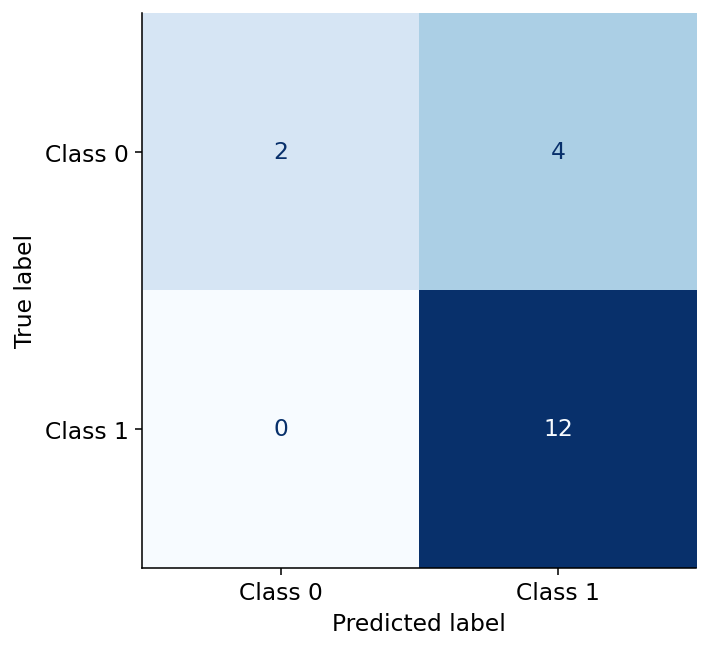

In [7]:
from IPython.display import Image, display
display(Image(filename='figures/confusion.png'))

### Dash All

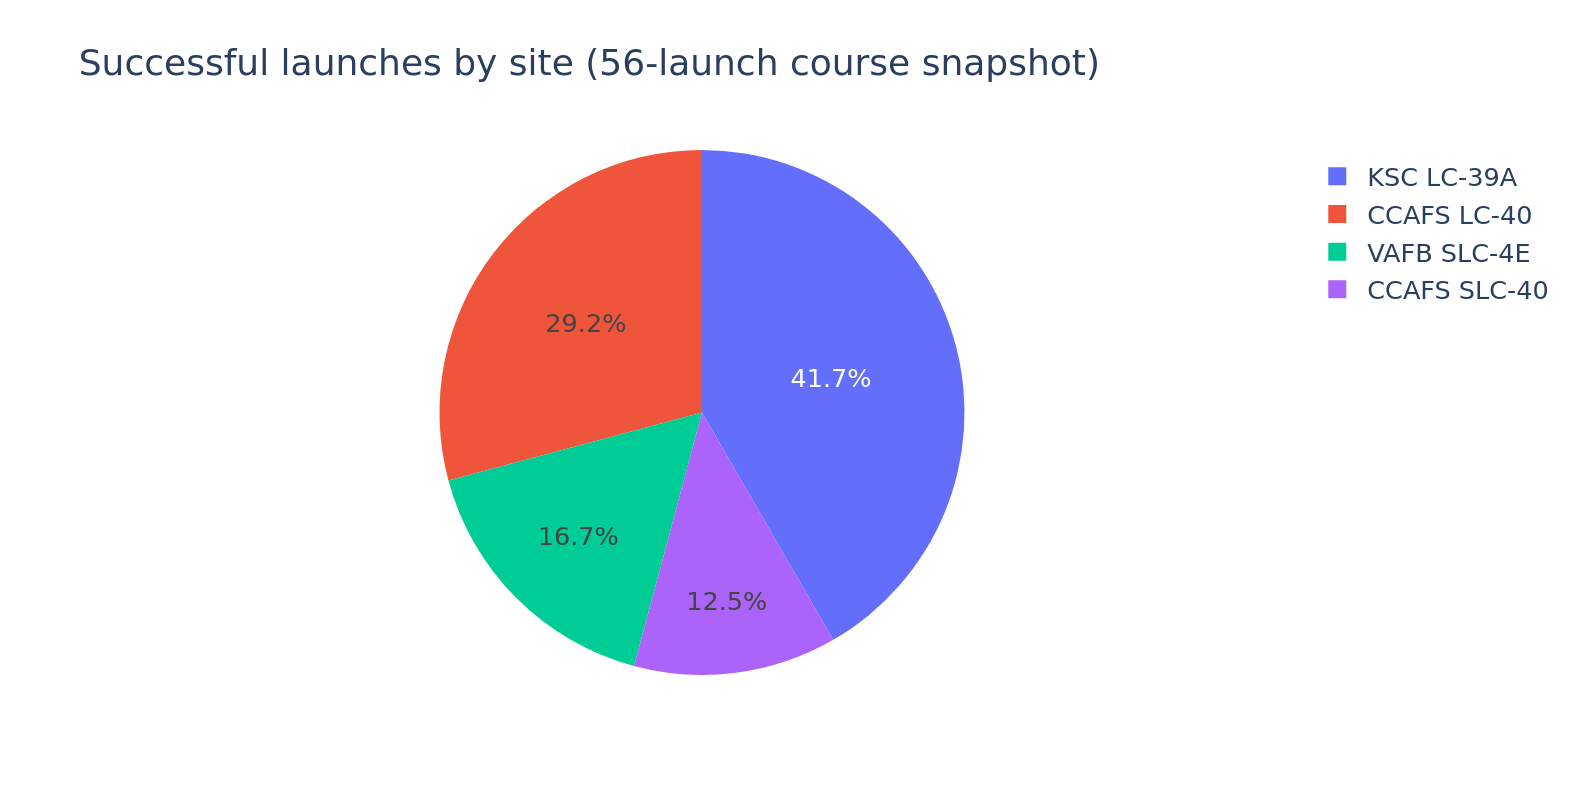

In [8]:
from IPython.display import Image, display
display(Image(filename='figures/dash_all.png'))

### Dash Best

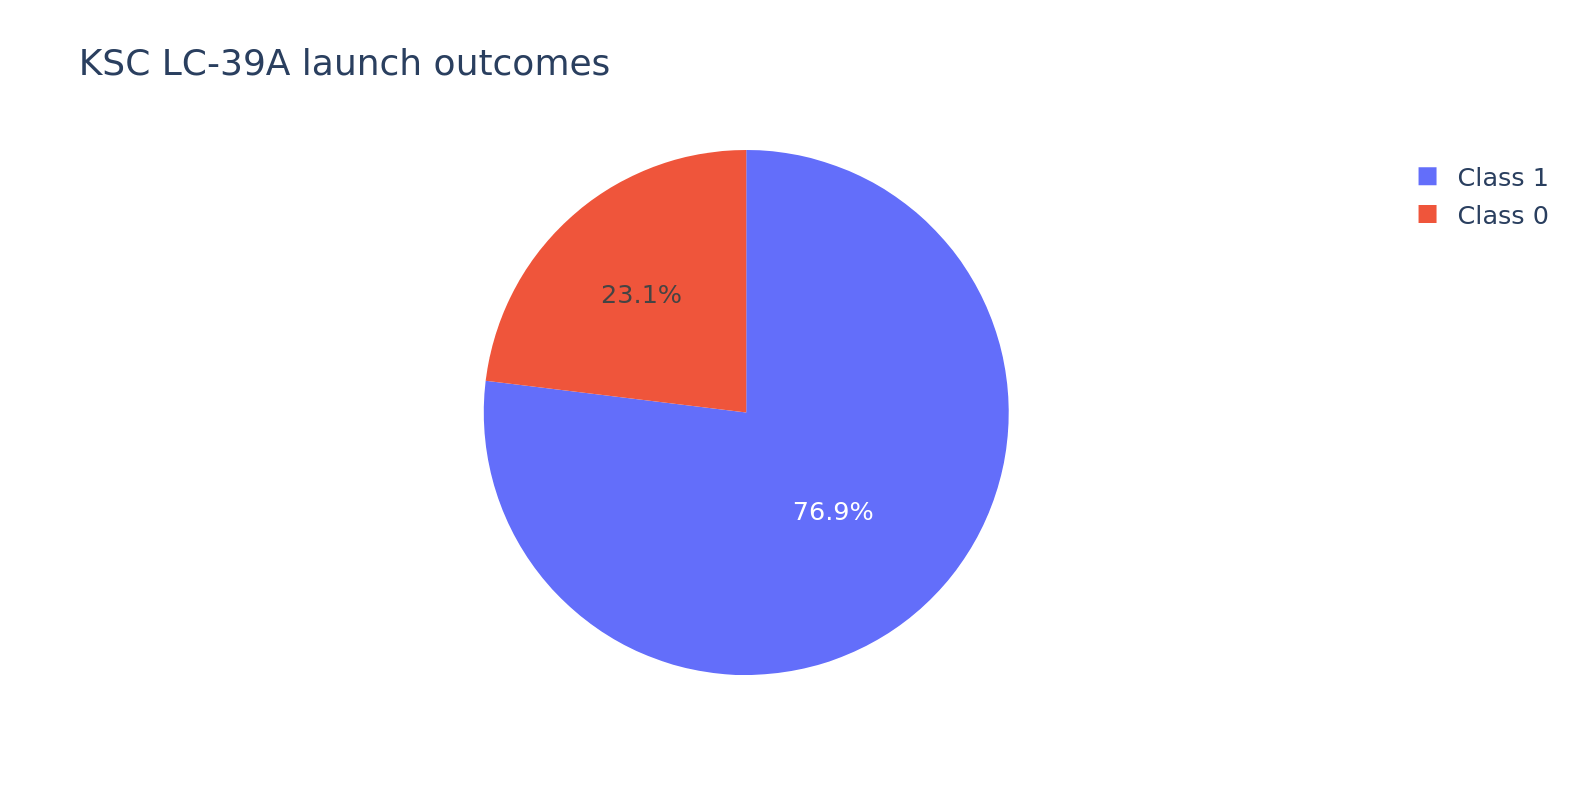

In [9]:
from IPython.display import Image, display
display(Image(filename='figures/dash_best.png'))

### Dash Filtered

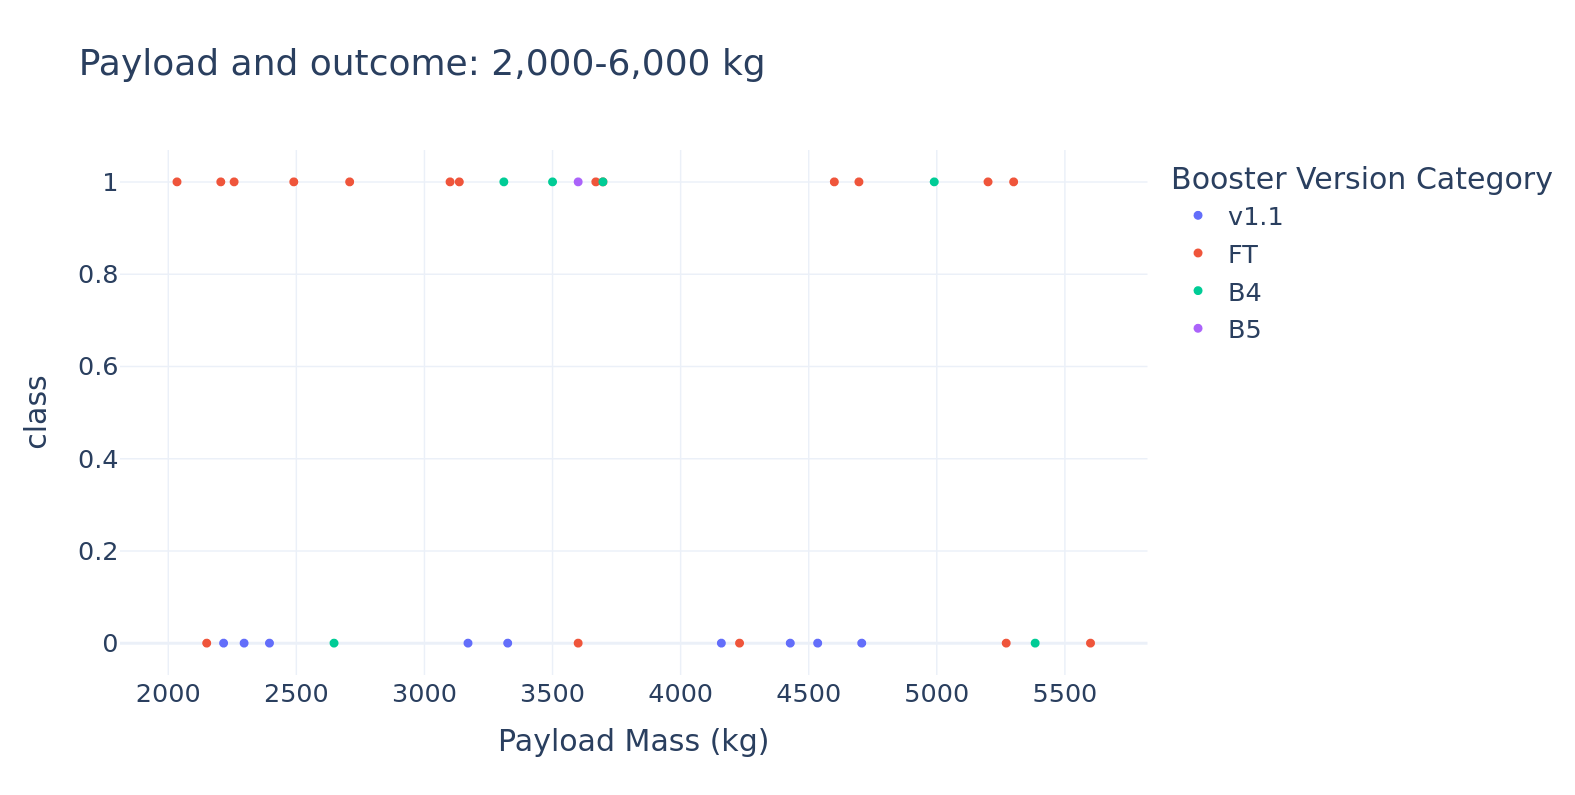

In [10]:
from IPython.display import Image, display
display(Image(filename='figures/dash_filtered.png'))

### Dash Scatter

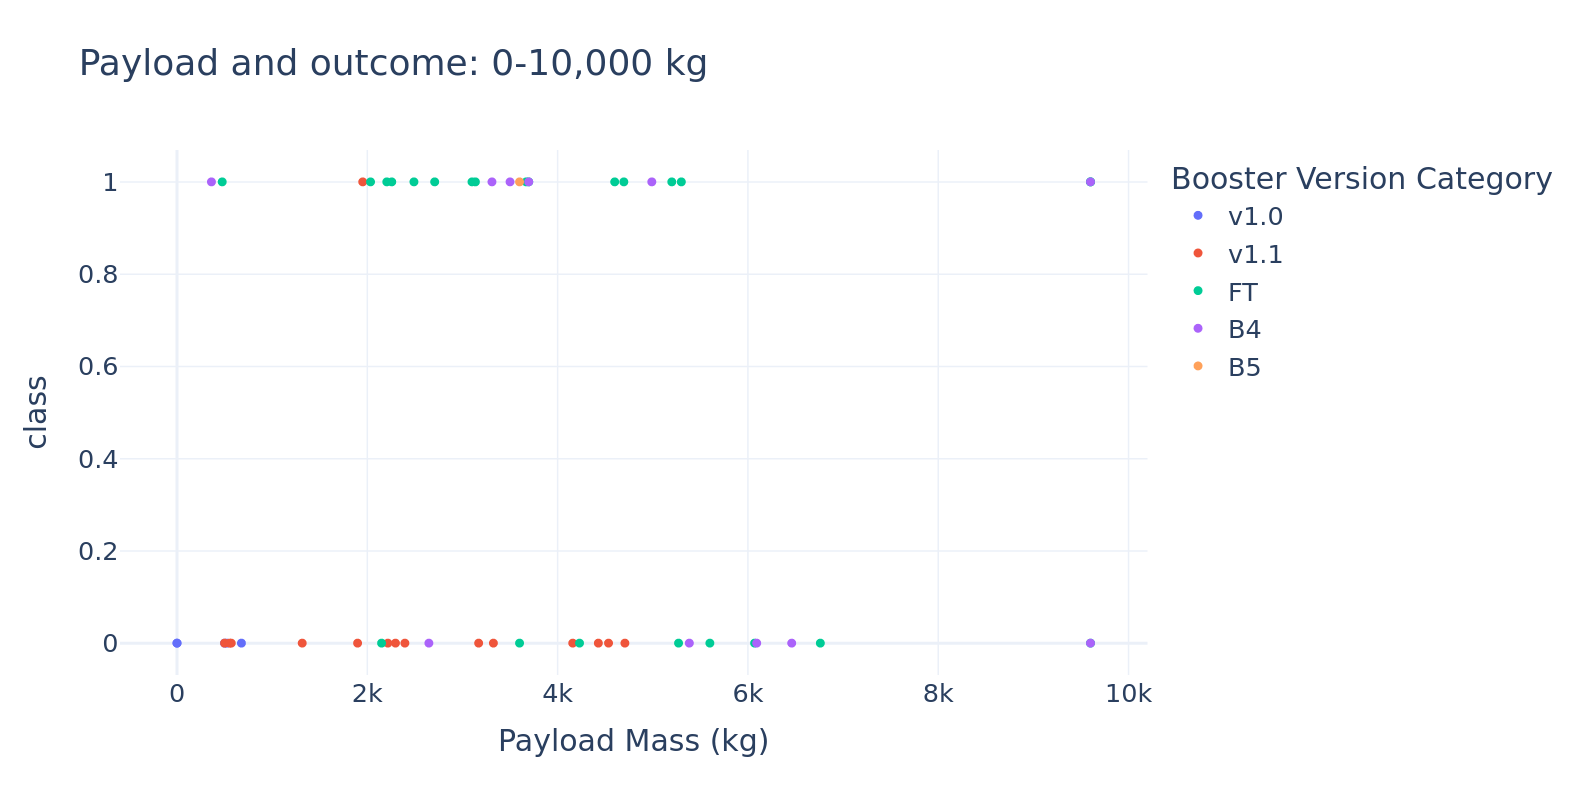

In [11]:
from IPython.display import Image, display
display(Image(filename='figures/dash_scatter.png'))

### Flight Orbit

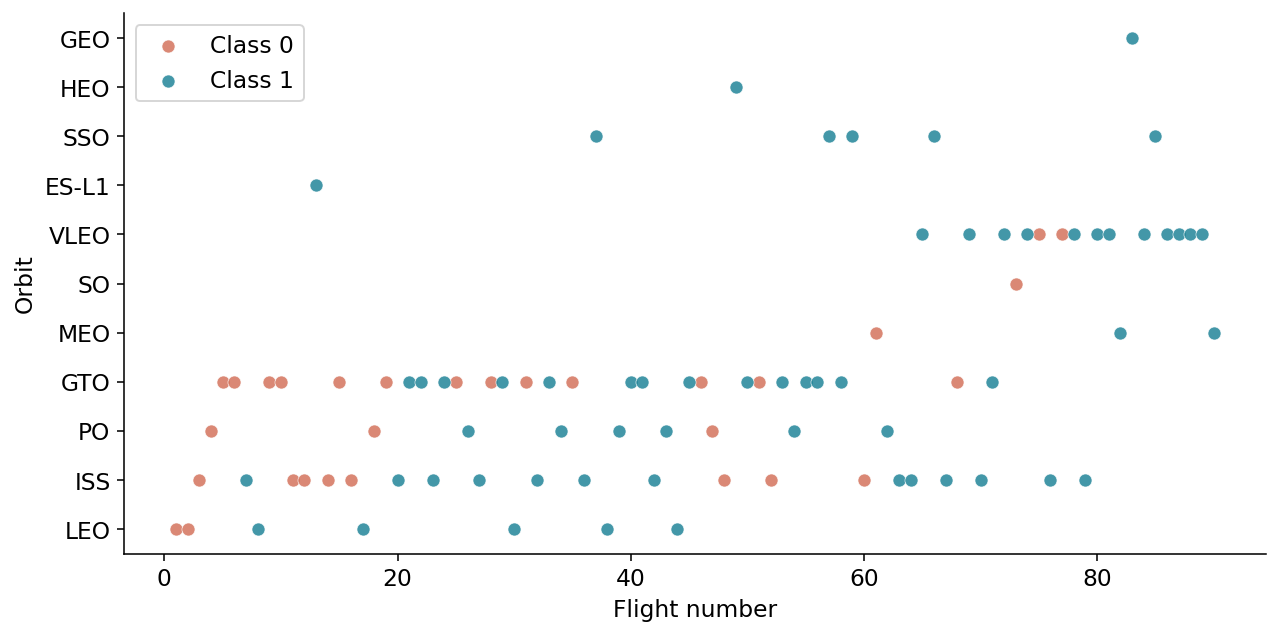

In [12]:
from IPython.display import Image, display
display(Image(filename='figures/flight_orbit.png'))

### Flight Site

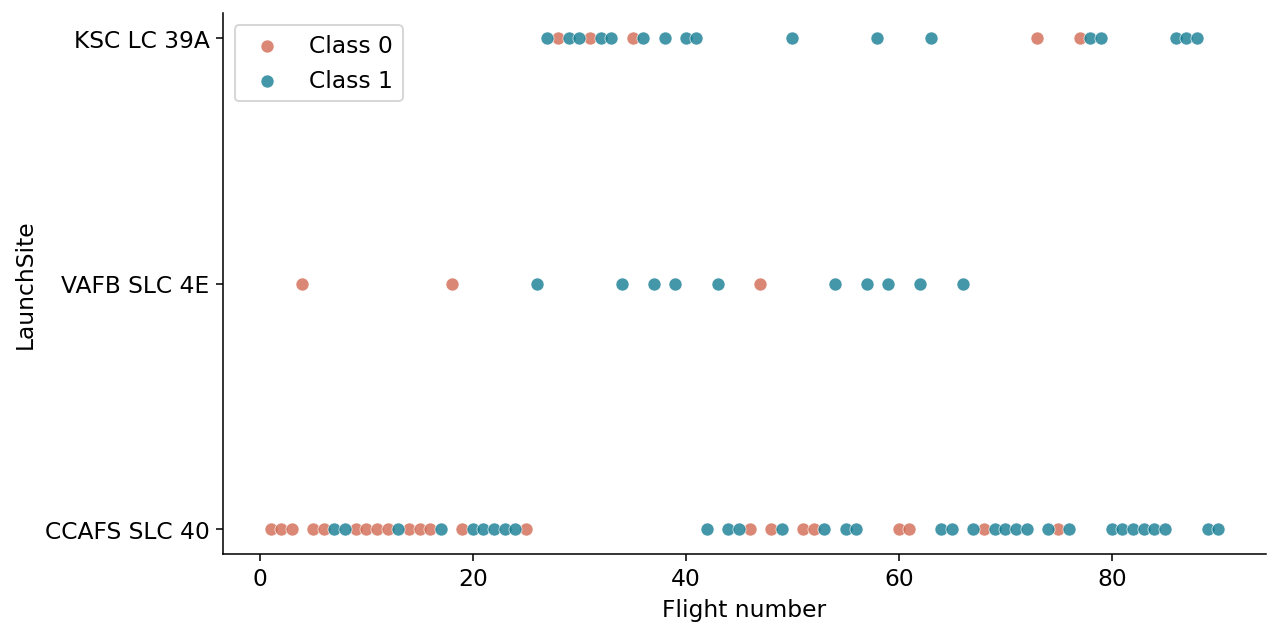

In [13]:
from IPython.display import Image, display
display(Image(filename='figures/flight_site.png'))

### Map Outcomes

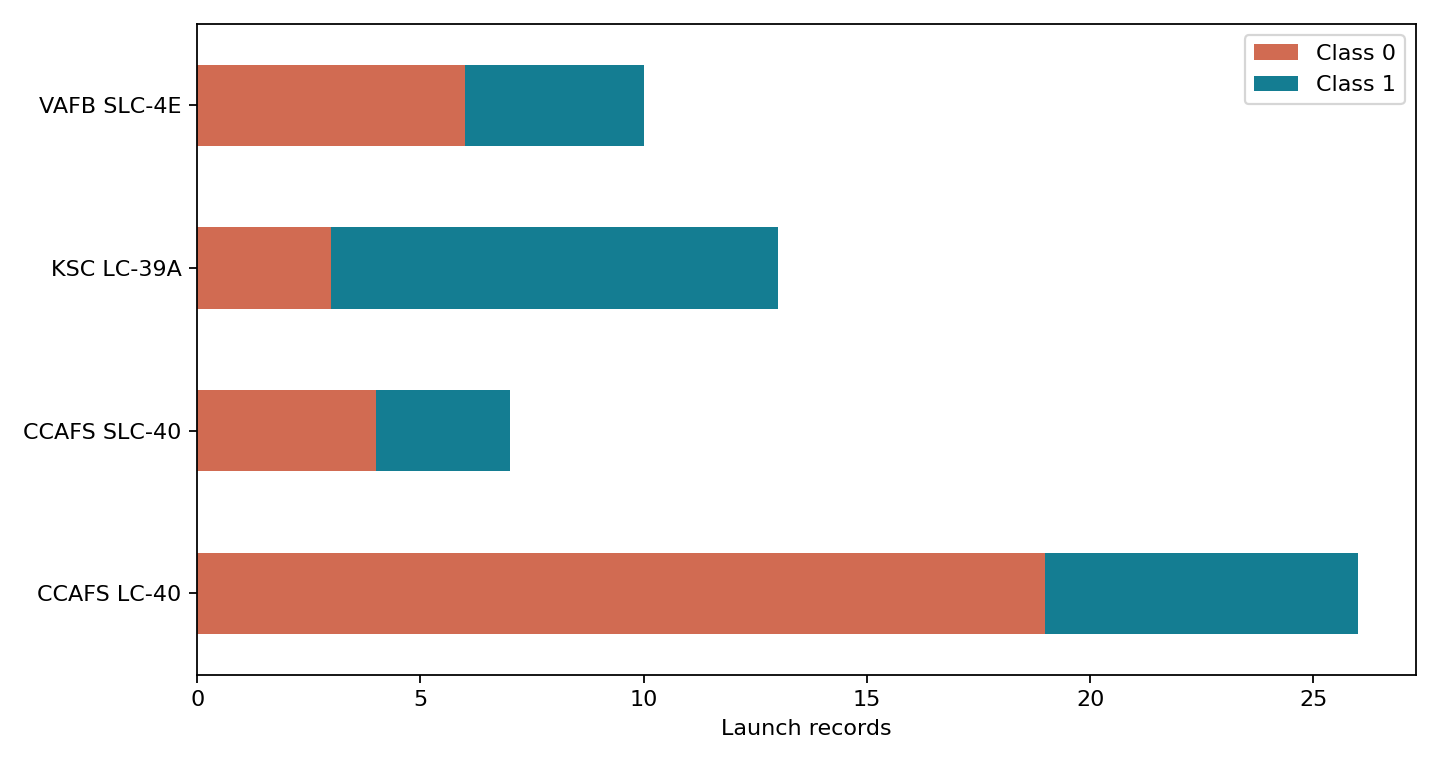

In [14]:
from IPython.display import Image, display
display(Image(filename='figures/map_outcomes.png'))

### Models

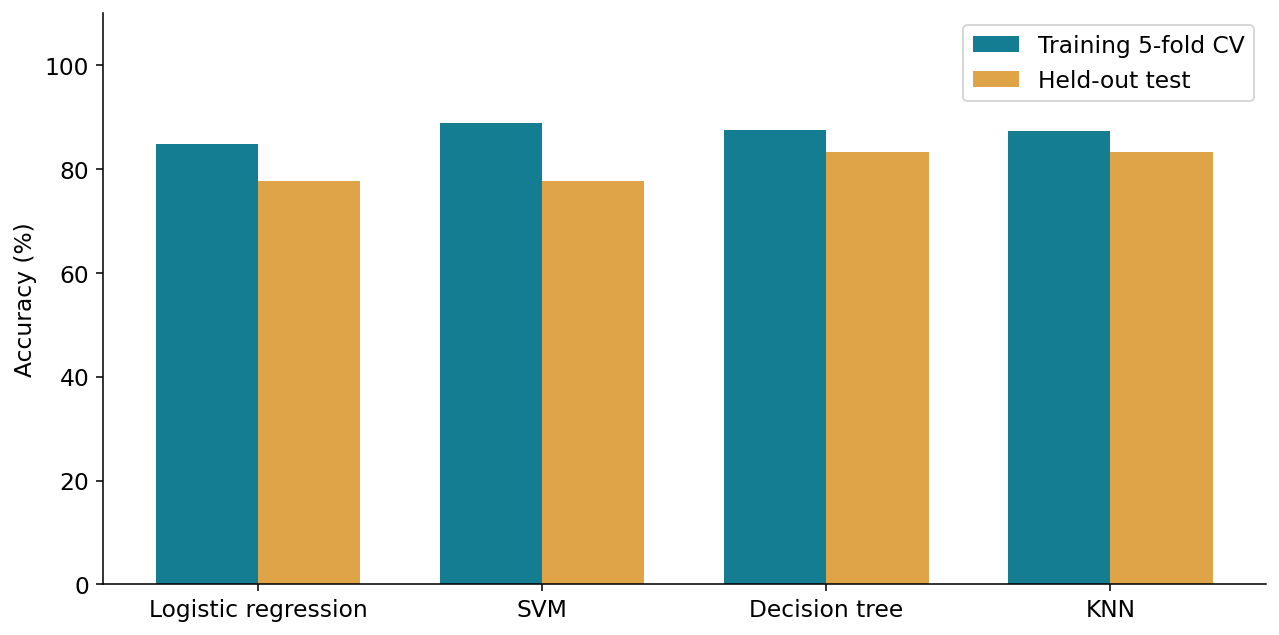

In [15]:
from IPython.display import Image, display
display(Image(filename='figures/models.png'))

### Orbit Rate

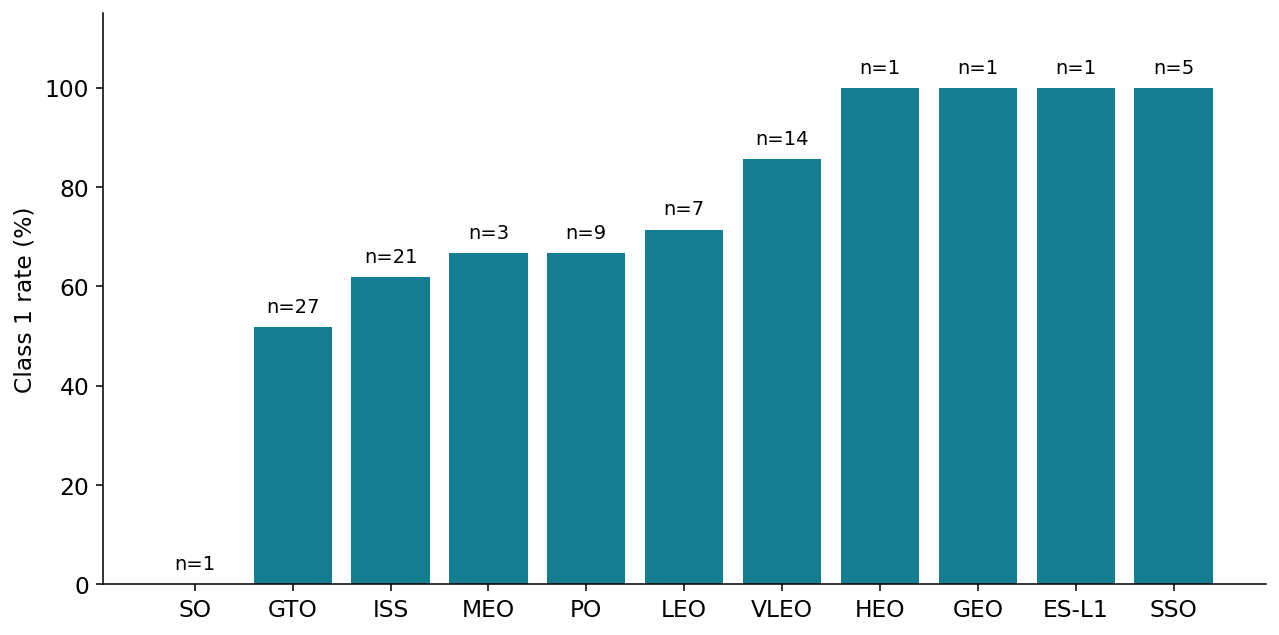

In [16]:
from IPython.display import Image, display
display(Image(filename='figures/orbit_rate.png'))

### Payload Orbit

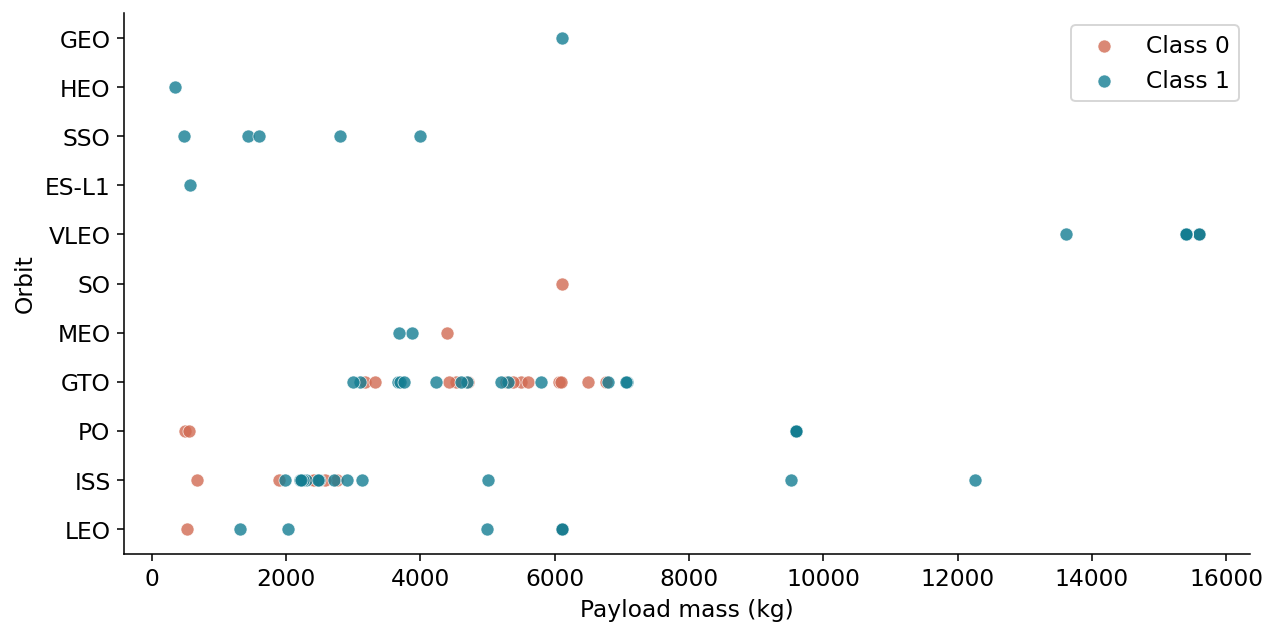

In [17]:
from IPython.display import Image, display
display(Image(filename='figures/payload_orbit.png'))

### Payload Site

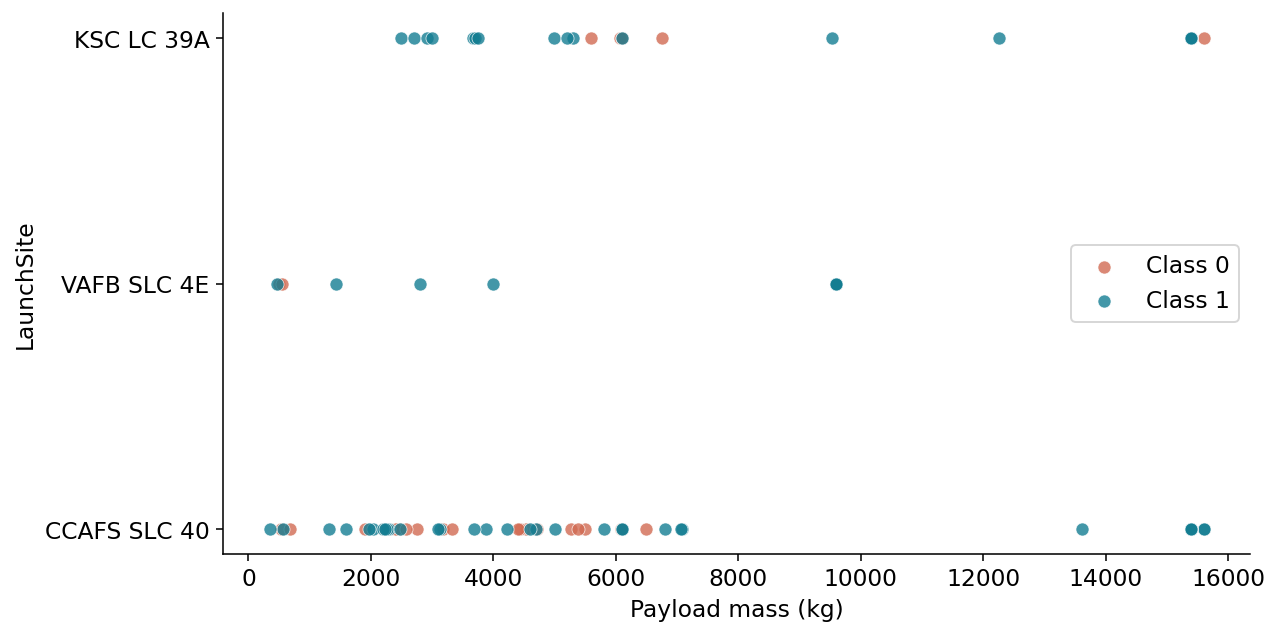

In [18]:
from IPython.display import Image, display
display(Image(filename='figures/payload_site.png'))

### Proximity

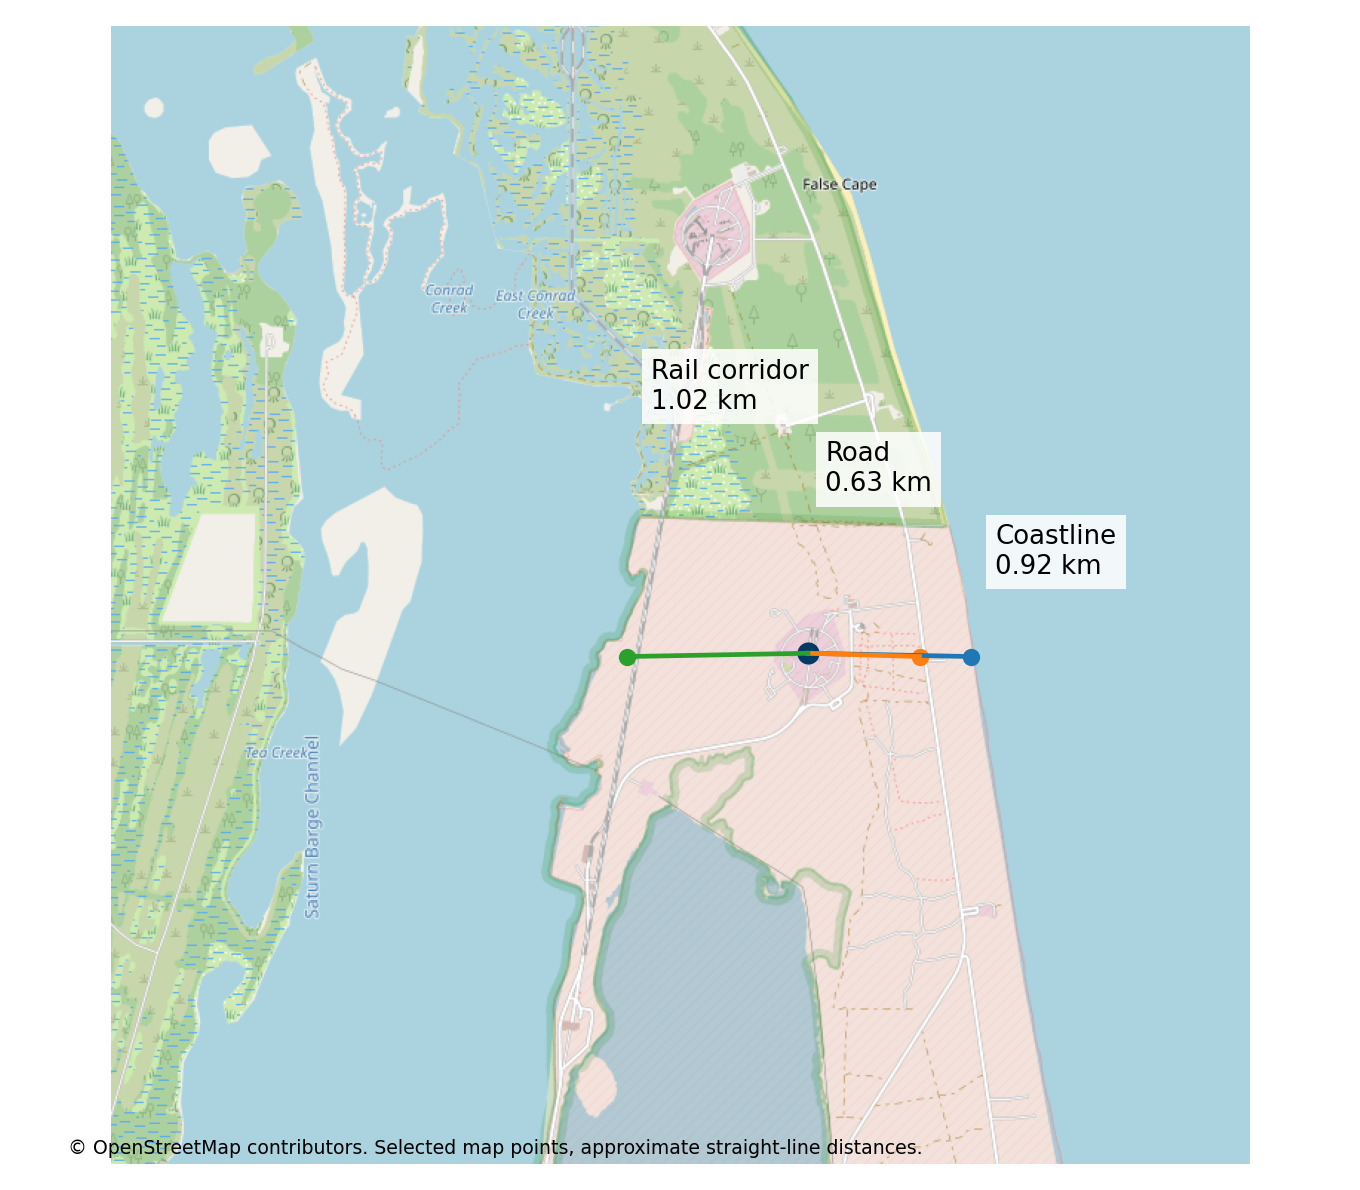

In [19]:
from IPython.display import Image, display
display(Image(filename='figures/proximity.png'))

### Site Locations

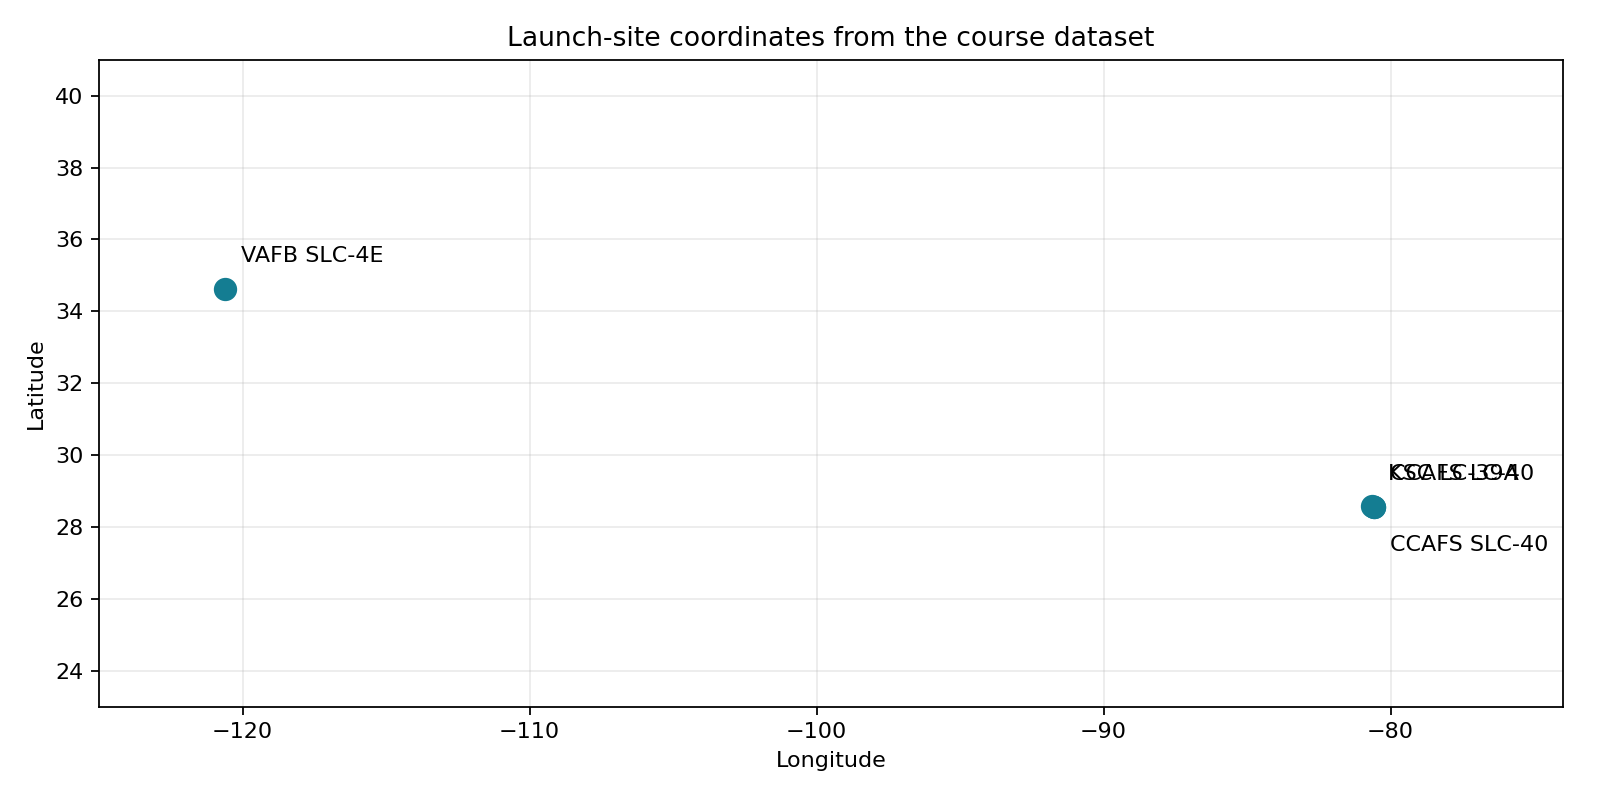

In [20]:
from IPython.display import Image, display
display(Image(filename='figures/site_locations.png'))

### Site Map

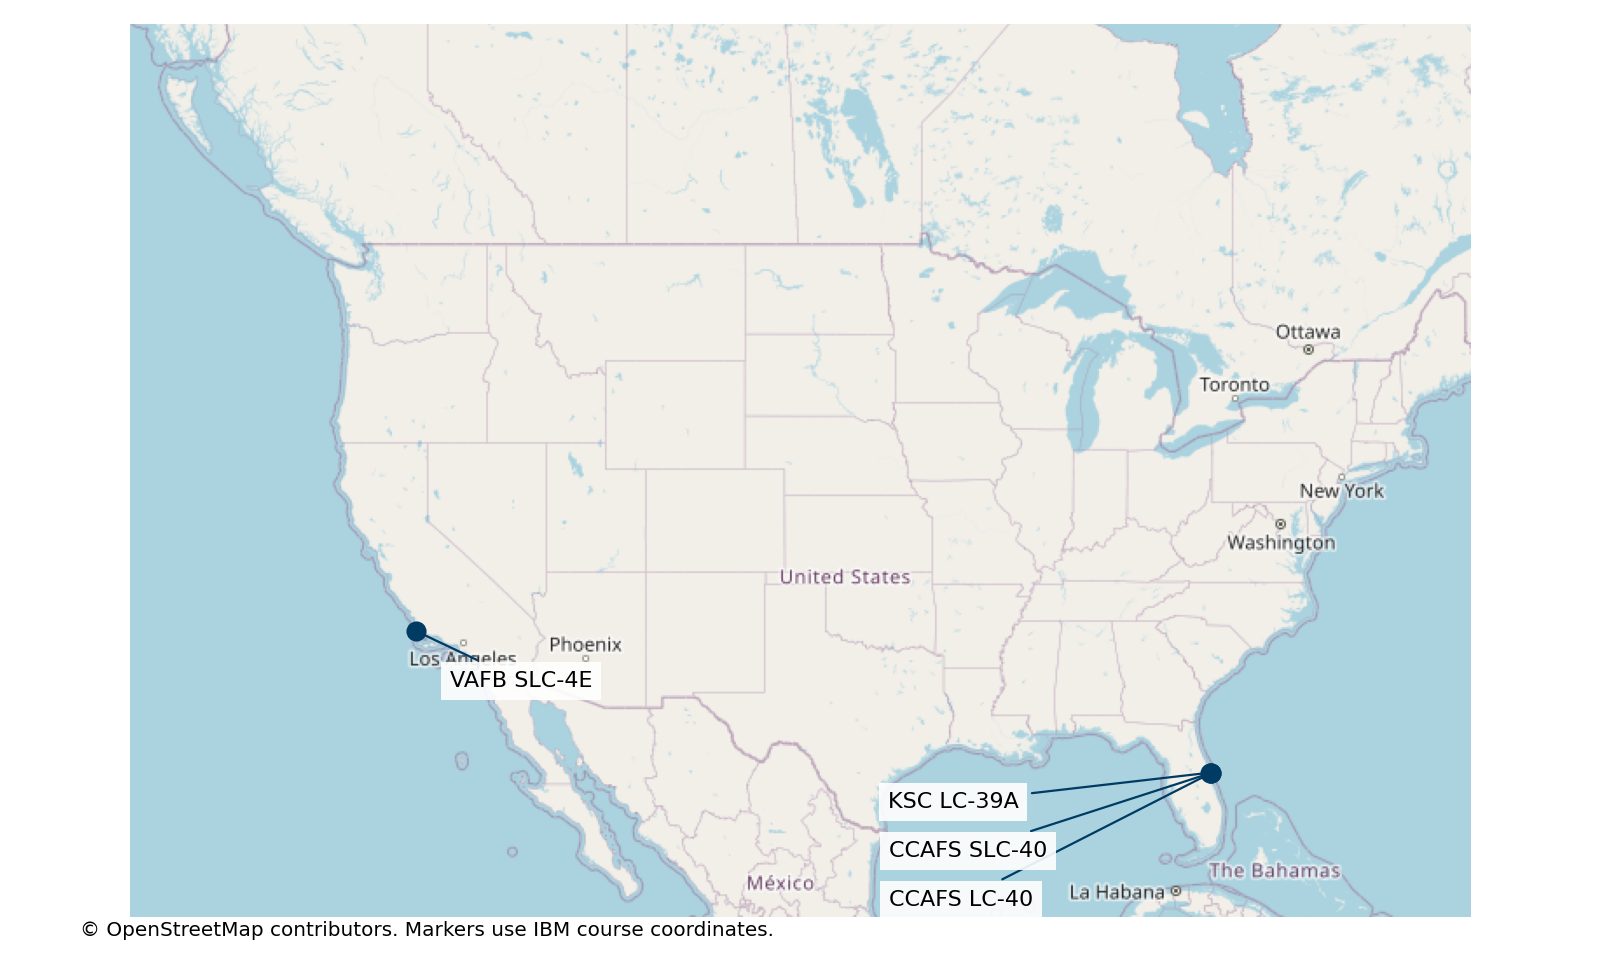

In [21]:
from IPython.display import Image, display
display(Image(filename='figures/site_map.png'))

### Yearly

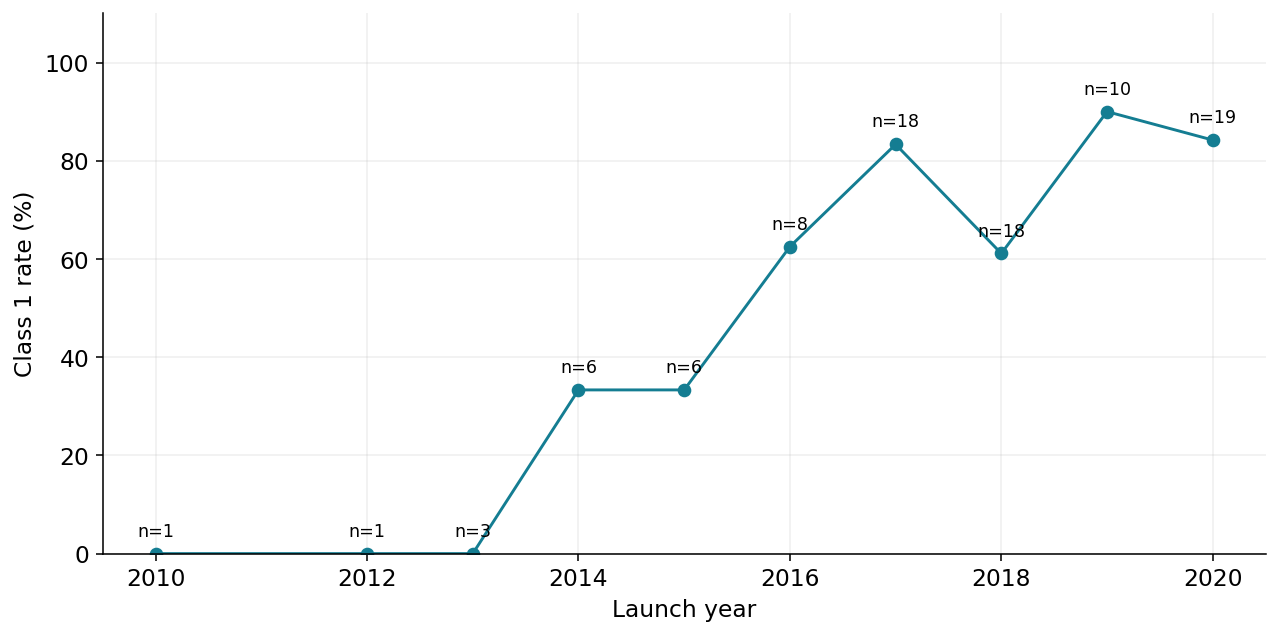

In [22]:
from IPython.display import Image, display
display(Image(filename='figures/yearly.png'))

## 7. Dashboard
Run python dashboard.py in a terminal. Use site dropdown and payload range slider. The app code is included below.

In [23]:
print(Path('dashboard.py').read_text())

from pathlib import Path
import pandas as pd
from dash import Dash, dcc, html, Input, Output
import plotly.express as px
df=pd.read_csv(Path(__file__).parent/'data/spacex_launch_dash.csv')
app=Dash(__name__)
app.layout=html.Div([
 html.H1('SpaceX Launch Records Dashboard'),
 html.P('Historical 56-launch IBM course snapshot. Class 1 and Class 0 follow course labels.'),
 dcc.Dropdown(id='site',options=[{'label':'All sites','value':'ALL'}]+[{'label':s,'value':s} for s in sorted(df['Launch Site'].unique())],value='ALL',clearable=False),
 dcc.Graph(id='pie'),html.Label('Payload mass range (kg)'),
 dcc.RangeSlider(id='payload',min=0,max=10000,step=100,value=[0,10000],marks={i:str(i) for i in range(0,10001,2000)}),dcc.Graph(id='scatter')
],style={'maxWidth':'1150px','margin':'auto','fontFamily':'Arial'})
@app.callback(Output('pie','figure'),Output('scatter','figure'),Input('site','value'),Input('payload','value'))
def update(site,payload):
 data=df if site=='ALL' else df[df['Launch Site']==si